# Predicting Cricket Batsmen's Career Runs using Regression
**Course:** AIC 301 – Machine Learning Lab | **Open Ended Lab I** | Bahria University, Islamabad Campus

**Objective:** Build regression models on a real-world dataset, compare them, and reflect on the results.

**Dataset:** `runs_of_batsmen.csv` – career batting statistics of about 7,000 international cricketers.
**Target (what we predict):** `Runs` – a player's total career runs (a continuous number, so regression fits).

| Lab requirement | Where in this notebook |
|---|---|
| 1. Dataset selection | Step 1 |
| 2. EDA (distributions, anomalies, correlations) | Step 3 |
| 3. At least two regression models + justification | Step 4 |
| 3. Optimise and compare (R², MSE) | Steps 5 and 6 |
| 4. Reflection and analysis | Step 7 |

## Step 1: Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('runs_of_batsmen.csv')
print('Rows, columns:', df.shape)
df.head()

Rows, columns: (7225, 11)


,Player Name,Years Active,Matches,Innings,Not Outs,Runs,High Score,Batting Average,Hundreds,Fifties,Ducks
0,SR Tendulkar (IND),1989-2013,664,782,74,34357,248*,48.52,100,164,34
1,KC Sangakkara (Asia/ICC/SL),2000-2015,594,666,67,28016,319,46.77,63,153,28
2,RT Ponting (AUS/ICC),1995-2012,560,668,70,27483,257,45.95,71,146,39
3,V Kohli (IND),2008-2024,538,601,87,27134,254*,52.78,80,141,38
4,DPMD Jayawardene (Asia/SL),1997-2015,652,725,62,25957,374,39.15,54,136,47


**Why this dataset?** `Runs` is a continuous target, and the other columns (innings, centuries, etc.) are natural things to predict it from.

## Step 2: Clean the data
Looking at the raw data, two things need fixing:
1. Missing values are written as `-` (so numbers were read as text).
2. `High Score` has a `*` for "not out" (e.g. `248*`).

In [2]:
# How many '-' (missing) values are in each column?
print((df == '-').sum())

Player Name          0
Years Active         0
Matches              0
Innings            247
Not Outs           247
Runs               247
High Score         247
Batting Average    563
Hundreds           247
Fifties            247
Ducks              247
dtype: int64


In [3]:
data = df.copy()

# 1) Turn '-' into a real missing value (NaN)
data = data.replace('-', np.nan)

# 2) Remove the '*' from High Score  ('248*' -> '248')
data['High Score'] = data['High Score'].str.replace('*', '', regex=False)

# 3) Convert the text columns into numbers
number_columns = ['Innings', 'Not Outs', 'Runs', 'High Score', 'Hundreds', 'Fifties', 'Ducks']
data[number_columns] = data[number_columns].apply(pd.to_numeric)

# 4) New feature: how many years the player was active  ('1989-2013' -> 25)
years = data['Years Active'].str.split('-', expand=True).astype(int)
data['Career Span'] = years[1] - years[0] + 1

# 5) Remove players who never batted (they have no runs data)
data = data.dropna(subset=['Runs'])
print('Players left:', len(data))

Players left: 6978


**Note – we do NOT use `Batting Average` as an input.** It is calculated as `Runs ÷ (Innings − Not Outs)`, so it already contains the answer. Using it would be cheating (called *data leakage*).

## Step 3: Exploratory Data Analysis (EDA)

In [4]:
features = ['Matches', 'Innings', 'Not Outs', 'High Score', 'Hundreds', 'Fifties', 'Ducks', 'Career Span']
target = 'Runs'

data[features + [target]].describe().round(1)

,Matches,Innings,Not Outs,High Score,Hundreds,Fifties,Ducks,Career Span,Runs
count,6978.0,6978.0,6978.0,6978.0,6978.0,6978.0,6978.0,6978.0,6978.0
mean,32.4,31.9,5.3,50.4,1.0,3.5,3.1,4.7,725.2
std,62.7,65.9,11.0,54.9,4.5,11.7,5.6,4.5,2154.9
min,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
25%,4.0,3.0,0.0,12.0,0.0,0.0,0.0,1.0,20.0
50%,10.0,9.0,2.0,32.0,0.0,0.0,1.0,3.0,95.0
75%,30.0,29.0,5.0,69.0,0.0,1.0,3.0,6.0,434.8
max,664.0,782.0,160.0,400.0,100.0,164.0,59.0,32.0,34357.0


The **mean** of Runs is much bigger than the **median** (50%), so a few players have huge totals. Let's see this in charts.

### 3.1 Distributions

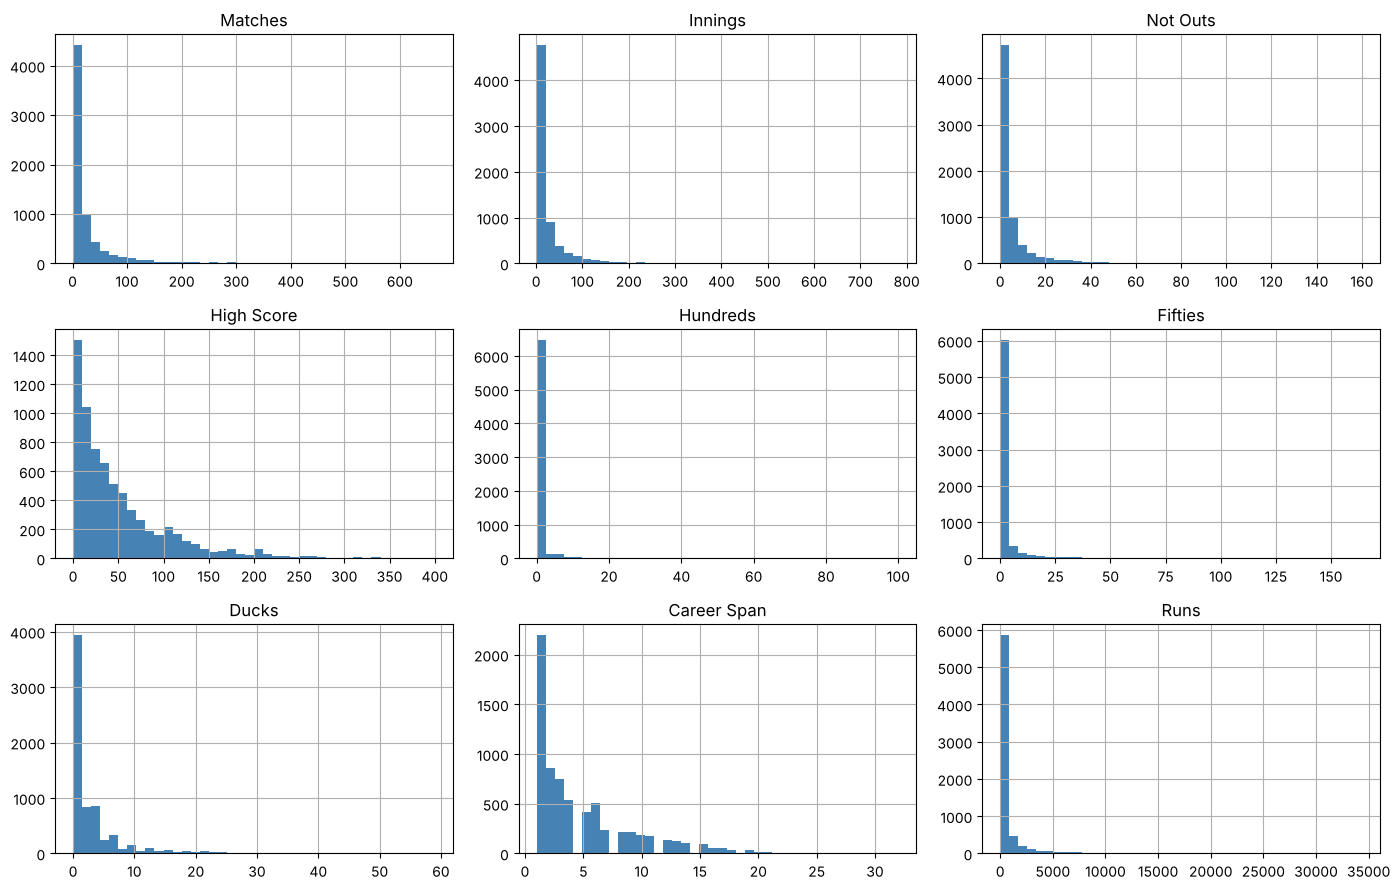

In [5]:
data[features + [target]].hist(bins=40, figsize=(14, 9), color='steelblue')
plt.tight_layout()
plt.show()

**Finding:** every column is *right-skewed* – most players have short careers and low numbers, and only a few have very large ones.

### 3.2 Anomalies (outliers)

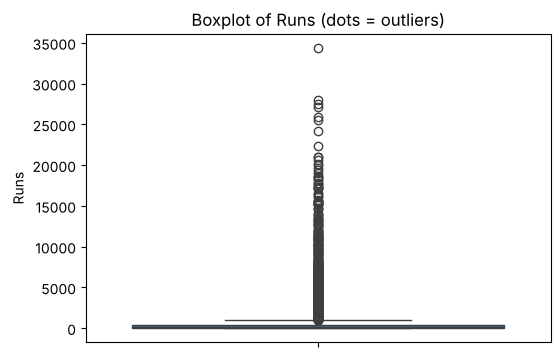

,Player Name,Matches,Innings,Runs
0,SR Tendulkar (IND),664,782.0,34357.0
1,KC Sangakkara (Asia/ICC/SL),594,666.0,28016.0
2,RT Ponting (AUS/ICC),560,668.0,27483.0
3,V Kohli (IND),538,601.0,27134.0
4,DPMD Jayawardene (Asia/SL),652,725.0,25957.0


In [6]:
plt.figure(figsize=(6, 4))
sns.boxplot(y=data['Runs'])
plt.title('Boxplot of Runs (dots = outliers)')
plt.show()

# Who are the extreme players?
data.sort_values('Runs', ascending=False).head(5)[['Player Name', 'Matches', 'Innings', 'Runs']]

In [7]:
# Check for impossible values (these would be data errors)
print('Players with Not Outs > Innings:', (data['Not Outs'] > data['Innings']).sum())
print('Players with Runs < High Score :', (data['Runs'] < data['High Score']).sum())

Players with Not Outs > Innings: 0
Players with Runs < High Score : 0


**Finding:** the outliers are real legends (Tendulkar, Sangakkara, Ponting …), not mistakes, and the checks found no impossible values. We **keep** them, since removing them would remove exactly the high range we want to predict.

### 3.3 Correlations

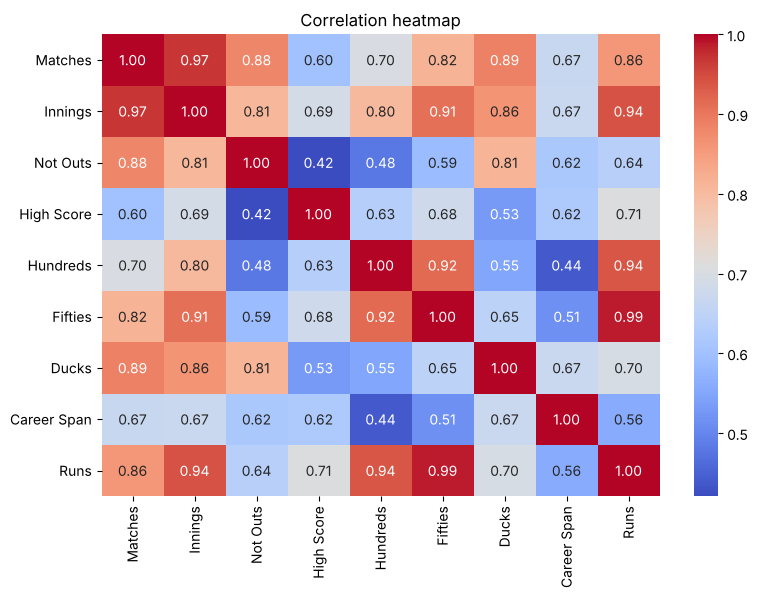

Fifties        0.986
Innings        0.942
Hundreds       0.938
Matches        0.858
High Score     0.706
Ducks          0.696
Not Outs       0.637
Career Span    0.558
dtype: float64

In [8]:
plt.figure(figsize=(9, 6))
sns.heatmap(data[features + [target]].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap')
plt.show()

# Correlation of each feature with Runs only
data[features].corrwith(data[target]).sort_values(ascending=False).round(3)

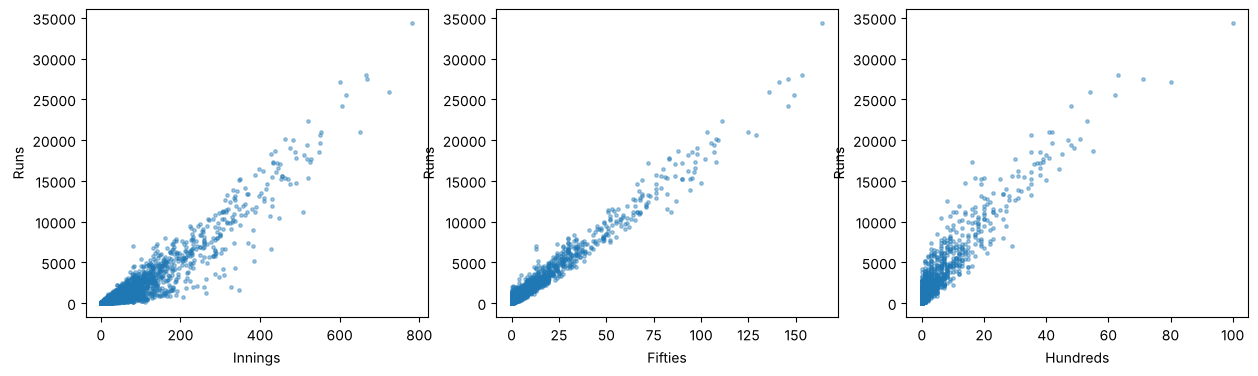

In [9]:
# Scatter plots: Runs vs the 3 strongest features
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Innings', 'Fifties', 'Hundreds']):
    ax.scatter(data[col], data['Runs'], s=6, alpha=0.4)
    ax.set_xlabel(col)
    ax.set_ylabel('Runs')
plt.show()

**Findings**
- `Fifties`, `Innings` and `Hundreds` have a very strong positive relationship with `Runs` (correlation about 0.94 to 0.99).
- Several features are strongly related to each other (e.g. Matches and Innings). This is called *multicollinearity*.
- The scatter plots show a rising trend that is slightly curved, which suggests a polynomial model could help.

## Step 4: Build the regression models
### 4.1 Split into training and testing data
We train the model on 80% of the players and keep 20% hidden. The hidden 20% tells us how the model performs on **new** players.

In [10]:
from sklearn.model_selection import train_test_split

X = data[features]   # inputs
y = data[target]     # what we predict

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training players:', len(X_train), '| Testing players:', len(X_test))

Training players: 5582 | Testing players: 1396


In [11]:
# A small helper so every model is scored the same way
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def score(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'R2': r2_score(y_true, y_pred), 'MSE': mse, 'RMSE': mse ** 0.5, 'MAE': mean_absolute_error(y_true, y_pred)}

Metrics used:
- **R²** – how much of the variation in runs the model explains (1 = perfect, higher is better).
- **MSE** – average of squared errors (lower is better).
- **RMSE** – square root of MSE, in "runs" (easier to interpret).
- **MAE** – average size of the error in runs.

### 4.2 Model 1 – Simple Linear Regression
**Idea:** predict runs from **one** feature, `Innings`:  `Runs = a + b × Innings`.

**Why this model?** Innings has a very strong relationship with Runs, and a straight line is the easiest model to understand. It is our **baseline** – other models must beat it.

In [12]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression()
model1.fit(X_train[['Innings']], y_train)             # learn from training data
pred1 = model1.predict(X_test[['Innings']])           # predict for unseen players

print(f'Runs = {model1.intercept_:.1f} + {model1.coef_[0]:.1f} x Innings')
print('Meaning: every extra innings adds about', round(model1.coef_[0]), 'career runs.')
score1 = score(y_test, pred1)
score1

Runs = -261.4 + 31.1 x Innings
Meaning: every extra innings adds about 31 career runs.


{'R2': 0.8991592444899481,
 'MSE': 463555.52446425625,
 'RMSE': 680.8491201905575,
 'MAE': 344.0239623108474}

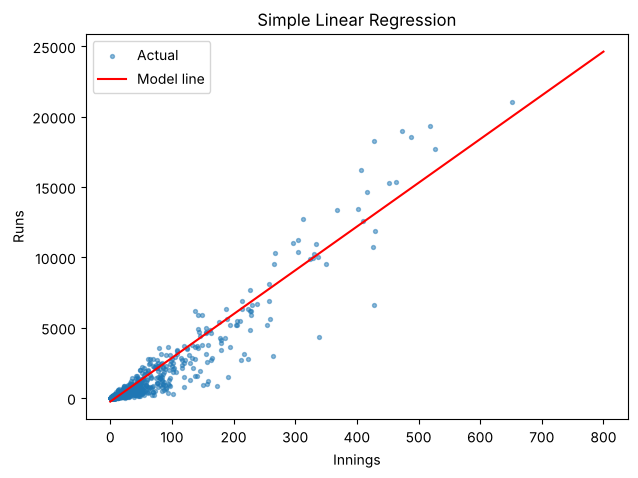

In [13]:
plt.figure(figsize=(7, 5))
plt.scatter(X_test['Innings'], y_test, s=8, alpha=0.5, label='Actual')
line_x = pd.DataFrame({'Innings': np.linspace(0, 800, 100)})
plt.plot(line_x, model1.predict(line_x), color='red', label='Model line')
plt.xlabel('Innings'); plt.ylabel('Runs'); plt.legend()
plt.title('Simple Linear Regression')
plt.show()

### 4.3 Model 2 – Multiple Linear Regression
**Idea:** use **all 8 features** together:  `Runs = a + b1×Matches + b2×Innings + b3×Hundreds + ...`

**Why this model?** Innings only tells us *how much* a player batted. Fifties, hundreds, ducks and high score tell us *how well* he batted. Using them all should predict better than innings alone.

In [14]:
model2 = LinearRegression()
model2.fit(X_train, y_train)
pred2 = model2.predict(X_test)

score2 = score(y_test, pred2)
score2

{'R2': 0.9976389833206579,
 'MSE': 10853.372919763335,
 'RMSE': 104.17952255488281,
 'MAE': 55.44586166525303}

In [15]:
# Which features matter most? (coefficient = effect of +1 on that feature)
pd.Series(model2.coef_, index=features).round(2)

Matches         -1.45
Innings         18.27
Not Outs        -7.75
High Score       0.44
Hundreds       125.14
Fifties         64.32
Ducks          -32.97
Career Span     -4.29
dtype: float64

### 4.4 Model 3 – Polynomial Regression
**Idea:** add squared terms and feature combinations (e.g. `Innings²`, `Innings × Hundreds`) so the model can fit **curves**.

**Why this model?** The scatter plots were slightly curved, and features work together (a player with many innings *and* many hundreds scores disproportionately more). A straight line cannot capture this.

We first *scale* the features (so they are all on a similar range) and then create the polynomial terms.

In [16]:
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

# Scale: make every feature have mean 0 and spread 1 (fit on training data only)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Create polynomial terms of degree 2
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_train_p2 = poly2.fit_transform(X_train_s)
X_test_p2 = poly2.transform(X_test_s)
print('Features before:', X_train_s.shape[1], '| after degree 2:', X_train_p2.shape[1])

model3 = LinearRegression()
model3.fit(X_train_p2, y_train)
pred3 = model3.predict(X_test_p2)

score3 = score(y_test, pred3)
score3

Features before: 8 | after degree 2: 44


{'R2': 0.997839153328627,
 'MSE': 9933.210109034351,
 'RMSE': 99.66549106403053,
 'MAE': 51.22508749835856}

#### Visualising the polynomial curve (Innings only)
The polynomial model above uses 8 features, so it cannot be drawn as a single 2D curve. To *see* what "polynomial" means, the plot below fits the same idea using **only `Innings`**: degree 1 is a straight line, while degrees 2 and 3 can bend to follow the data.

(The straight red dashed line in the *Actual vs Predicted* charts later is only the "perfect prediction" reference line, not the model.)

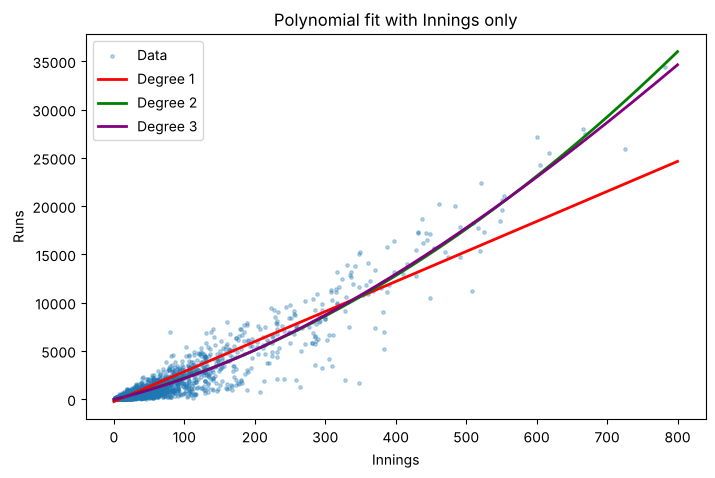

In [17]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train['Innings'], y_train, s=6, alpha=0.3, label='Data')

line_x = pd.DataFrame({'Innings': np.linspace(0, 800, 200)})
for degree, color in [(1, 'red'), (2, 'green'), (3, 'purple')]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    m = LinearRegression().fit(poly.fit_transform(X_train[['Innings']]), y_train)
    plt.plot(line_x, m.predict(poly.transform(line_x)), color=color, lw=2, label=f'Degree {degree}')

plt.xlabel('Innings'); plt.ylabel('Runs'); plt.legend()
plt.title('Polynomial fit with Innings only')
plt.show()

## Step 5: Optimise the models
Optimising means finding the best *settings*. We use **cross-validation**: the training data is split into 5 parts; the model trains on 4 parts and is checked on the 5th, rotating 5 times. The average score is reliable and we never touch the test data.

### 5.1 Polynomial model – which degree is best?

In [18]:
from sklearn.model_selection import cross_val_score

for degree in [1, 2, 3]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    Xp = poly.fit_transform(X_train_s)
    cv_r2 = cross_val_score(LinearRegression(), Xp, y_train, cv=5, scoring='r2').mean()
    print(f'Degree {degree}: {Xp.shape[1]:3d} features | cross-validated R2 = {cv_r2:.4f}')

Degree 1:   8 features | cross-validated R2 = 0.9976
Degree 2:  44 features | cross-validated R2 = 0.9982


Degree 3: 164 features | cross-validated R2 = 0.9745


Degree 2 gives the best score. Degree 3 has far more terms and starts to **over-fit** (memorise the training data), so its score drops. We keep **degree 2**.

### 5.2 Add regularisation (Ridge) to the polynomial model
Polynomial terms are strongly related to each other, which can make a model unstable. **Ridge regression** adds a penalty (`alpha`) that keeps the coefficients small. We test several `alpha` values:

In [19]:
from sklearn.linear_model import Ridge

cv_scores = {}
for alpha in [0.01, 0.1, 1, 10, 100, 1000]:
    cv_scores[alpha] = cross_val_score(Ridge(alpha=alpha), X_train_p2, y_train, cv=5, scoring='r2').mean()
    print(f'alpha = {alpha:>7}: cross-validated R2 = {cv_scores[alpha]:.5f}')

best_alpha = max(cv_scores, key=cv_scores.get)   # the alpha with the highest score
print('Best alpha:', best_alpha)

alpha =    0.01: cross-validated R2 = 0.99818
alpha =     0.1: cross-validated R2 = 0.99818
alpha =       1: cross-validated R2 = 0.99817
alpha =      10: cross-validated R2 = 0.99807


alpha =     100: cross-validated R2 = 0.99631
alpha =    1000: cross-validated R2 = 0.98110
Best alpha: 0.01


In [20]:
# Train the optimised model using the best alpha found above
model3_opt = Ridge(alpha=best_alpha)
model3_opt.fit(X_train_p2, y_train)
pred3_opt = model3_opt.predict(X_test_p2)

score3_opt = score(y_test, pred3_opt)
score3_opt

{'R2': 0.9978391558477165,
 'MSE': 9933.198529015663,
 'RMSE': 99.66543296958912,
 'MAE': 51.224289940877945}

### 5.3 Multiple linear model – optimise with Ridge too
(For a fair comparison, the same regularisation idea is applied to Model 2.)

In [21]:
cv_scores = {}
for alpha in [0.01, 0.1, 1, 10, 100, 1000]:
    cv_scores[alpha] = cross_val_score(Ridge(alpha=alpha), X_train_s, y_train, cv=5, scoring='r2').mean()
    print(f'alpha = {alpha:>7}: cross-validated R2 = {cv_scores[alpha]:.5f}')

best_alpha_multi = max(cv_scores, key=cv_scores.get)
print('Best alpha:', best_alpha_multi)

alpha =    0.01: cross-validated R2 = 0.99760
alpha =     0.1: cross-validated R2 = 0.99760
alpha =       1: cross-validated R2 = 0.99760


alpha =      10: cross-validated R2 = 0.99754
alpha =     100: cross-validated R2 = 0.99661
alpha =    1000: cross-validated R2 = 0.98625
Best alpha: 0.1


In [22]:
model2_opt = Ridge(alpha=best_alpha_multi)
model2_opt.fit(X_train_s, y_train)
pred2_opt = model2_opt.predict(X_test_s)

score2_opt = score(y_test, pred2_opt)
score2_opt

{'R2': 0.9976392052298891,
 'MSE': 10852.35282377606,
 'RMSE': 104.17462658332911,
 'MAE': 55.44235128754829}

## Step 6: Compare all models on the test data

In [23]:
results = pd.DataFrame({
    '1. Simple Linear (Innings)':       score1,
    '2. Multiple Linear':               score2,
    '2b. Multiple Linear + Ridge':      score2_opt,
    '3. Polynomial (degree 2)':         score3,
    '3b. Polynomial + Ridge (optimised)': score3_opt,
}).T
results.round(3)

,R2,MSE,RMSE,MAE
1. Simple Linear (Innings),0.899,463555.524,680.849,344.024
2. Multiple Linear,0.998,10853.373,104.180,55.446
2b. Multiple Linear + Ridge,0.998,10852.353,104.175,55.442
3. Polynomial (degree 2),0.998,9933.210,99.665,51.225
3b. Polynomial + Ridge (optimised),0.998,9933.199,99.665,51.224


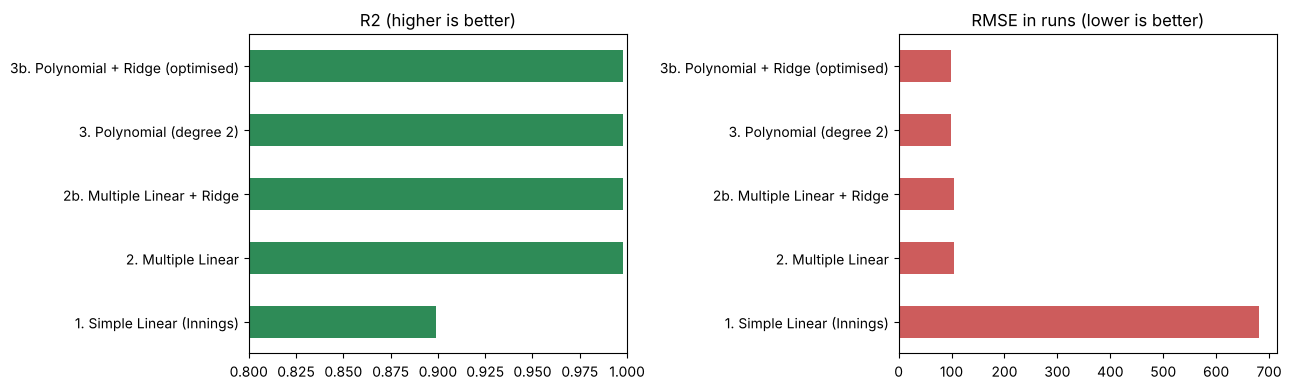

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results['R2'].plot.barh(ax=axes[0], color='seagreen')
axes[0].set_title('R2 (higher is better)'); axes[0].set_xlim(0.8, 1)
results['RMSE'].plot.barh(ax=axes[1], color='indianred')
axes[1].set_title('RMSE in runs (lower is better)')
plt.tight_layout(); plt.show()

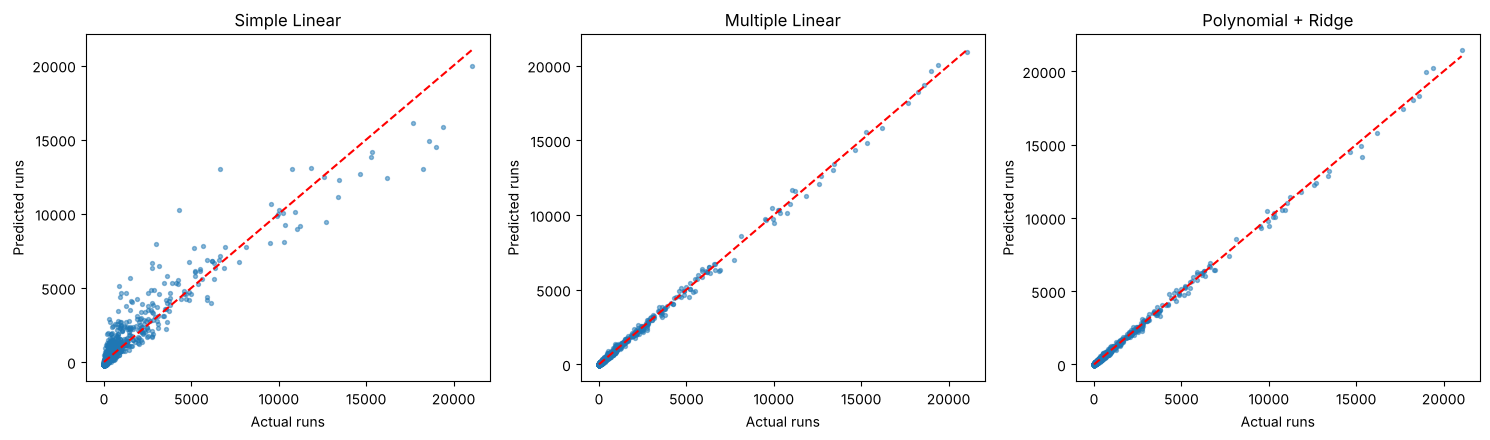

In [25]:
# Actual vs predicted: the closer to the red line, the better
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, pred) in zip(axes, [('Simple Linear', pred1), ('Multiple Linear', pred2_opt), ('Polynomial + Ridge', pred3_opt)]):
    ax.scatter(y_test, pred, s=8, alpha=0.5)
    ax.plot([0, y_test.max()], [0, y_test.max()], 'r--')
    ax.set_title(name); ax.set_xlabel('Actual runs'); ax.set_ylabel('Predicted runs')
plt.tight_layout(); plt.show()

In [26]:
# Where do the models make bigger mistakes: ordinary players or stars?
ordinary = y_test < 1000
for name, pred in [('Simple Linear', pred1), ('Multiple Linear', pred2_opt), ('Polynomial + Ridge', pred3_opt)]:
    err_ordinary = mean_absolute_error(y_test[ordinary], pred[ordinary])
    err_stars = mean_absolute_error(y_test[~ordinary], pred[~ordinary])
    print(f'{name:20s} average error: ordinary players = {err_ordinary:6.1f} runs | stars (>=1000 runs) = {err_stars:6.1f} runs')

Simple Linear        average error: ordinary players =  233.2 runs | stars (>=1000 runs) =  998.9 runs
Multiple Linear      average error: ordinary players =   37.1 runs | stars (>=1000 runs) =  164.0 runs
Polynomial + Ridge   average error: ordinary players =   32.9 runs | stars (>=1000 runs) =  159.7 runs


## Step 7: Reflection and Analysis

In [27]:
best = results['R2'].idxmax()
print('Best model:', best)
print(results.loc[best].round(3))

Best model: 3b. Polynomial + Ridge (optimised)
R2         0.998
MSE     9933.199
RMSE      99.665
MAE       51.224
Name: 3b. Polynomial + Ridge (optimised), dtype: float64


### 7.1 Challenges faced
1. **Messy data:** missing values were written as `-` and High Score contained `*`, so numbers were loaded as text. We had to clean and convert them.
2. **Missing information:** about 250 players who never batted had no stats and were removed.
3. **Data leakage:** `Batting Average` is calculated from `Runs`, so we excluded it.
4. **Skewed data and outliers:** a few legends have 25,000+ runs while most players have a few hundred. We kept them because they are real, but they cause the biggest errors.
5. **Related features (multicollinearity):** Matches, Innings, Fifties, etc. move together, which makes plain regression coefficients unstable. Ridge regularisation helps with this.

### 7.2 Which model performed better, and why?
| Model | Test R² | RMSE (runs) |
|---|---|---|
| Simple Linear (Innings) | ≈ 0.90 | ≈ 680 |
| Multiple Linear | ≈ 0.998 | ≈ 104 |
| Polynomial + Ridge | ≈ 0.998 | ≈ 100 |

*(Exact values are in the table in Step 6.)*

- **Simple linear regression** is a good starting point (R² ≈ 0.90), but it only knows how *many* innings a player batted, not how *well*. Two players with the same innings get the same prediction.
- **Multiple linear regression** was a big improvement, as the error dropped from ~680 to ~104 runs. Features like fifties and hundreds describe batting quality.
- **Polynomial regression (degree 2)** performed best, but only slightly better (RMSE ≈ 100 vs ≈ 104). The squared and interaction terms capture the curve in the data.
- **Ridge** made almost no difference here (the best alpha was tiny), because we have thousands of players and few features, so over-fitting was not a big problem. It would matter more with less data. The train and test scores were almost equal, so there is no serious over-fitting.
- **Why not higher degree?** Degree 3 added many more terms but did not improve the cross-validated score, which is a sign of over-fitting.

### 7.3 Limitations and future work
- Errors are largest for star players, because the data has few of them and the spread of runs grows with the number of innings. A log-transform of Runs might help.
- The dataset mixes Tests, ODIs and T20s, which have different scoring rates.
- Tree-based models (Random Forest, Gradient Boosting) could be tried as well.

### 7.4 Conclusion
Career runs can be predicted very accurately from career statistics. A single feature already explains about 90% of the variation, and adding more features and a degree-2 polynomial with Ridge raises it to about 99.8%. Cleaning the data properly (and avoiding leakage) was as important as choosing the model.